<div style="text-align: center;">
<h1 style="font-weight: bold; margin: 20px 0;">
Illustrating Climate News Headlines with CCI Data 
</h1>
</div>


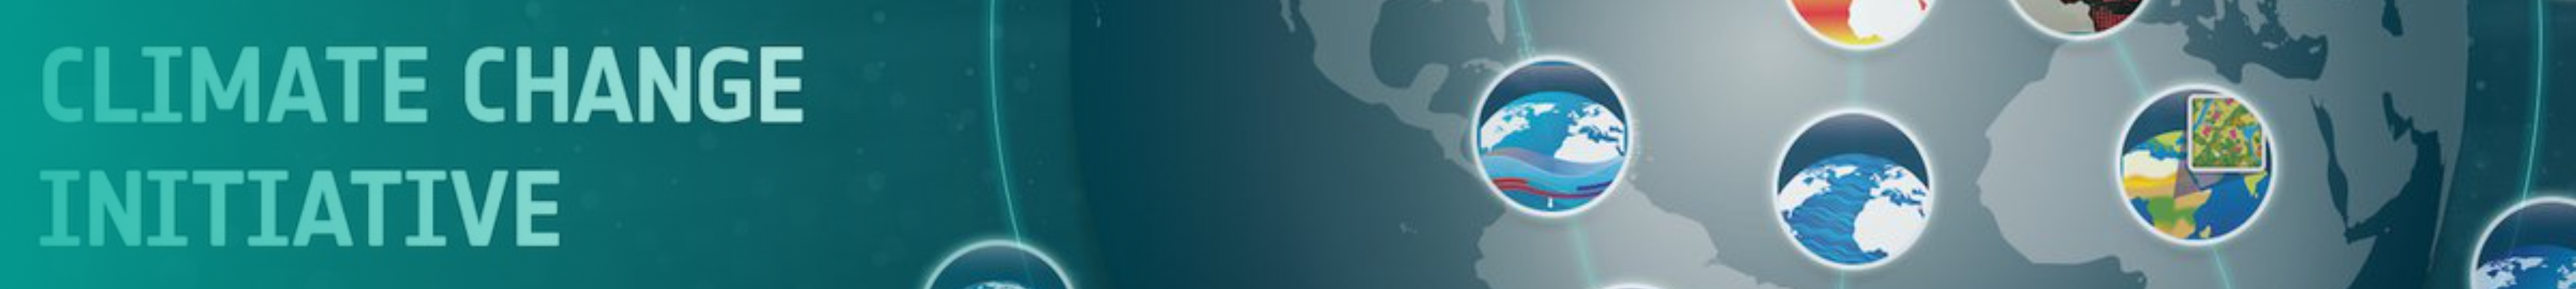

<div style="background-color: #e6f3ff;  padding: 10px; border-left: 5px solid #e6f3ff;">
<h2 style="margin: 0 0 15px 0; font-size: 1.4em;">1. Introduction:</h2>

In this beginner-friendly notebook, we will use real satellite-based data from the [ESA Climate Change Initiative (CCI)](https://climate.esa.int/en/odp/#/dashboard) to explore recent climate trends. The goal is to understand and **illustrate climate news headlines** using satellite-based measurements of essential climate variables.

We will use simple Python code and visualisations to explore questions such as:

* *Has global sea surface temperature an sea levels increased over the last decades?*
* *What did sea temperatures look like in record-warm years?*
* *What did LST and soil moisture conditions look like in record extreme fire events?*

This notebook is designed for **participants with no prior experience in Python or climate data analysis**. You will learn:

- How to access CCI climate data using the CCI Toolbox python Package
- How to navigate and subset climate data 
- How to create basic plots and statistics 
- How to save a figure you generated
- How to map and interpret ECVs changes over time and space
</div>

## Setup & Imports

Before we can start working with the data, we need to import a few Python libraries. These libraries provide useful tools for working with satellite data, performing simple calculations, and creating visualisations.

Don’t worry if you’re not familiar with these yet — we’ll explain what you need as we go.

In [6]:
# ESA Climate Toolbox imports for accessing and plotting ESA CCI data
from esa_climate_toolbox.core import get_op              # Get predefined operations (e.g., time series, averages)
from esa_climate_toolbox.core import list_ecv_datasets   # List available datasets per ECV (Essential Climate Variable)
from esa_climate_toolbox.core import get_store           # Connect to an ESA data store
from esa_climate_toolbox.core import list_datasets       # List all datasets in a store
from esa_climate_toolbox.core import open_data           # Open datasets with the toolbox
from esa_climate_toolbox.core import search              # 
from esa_climate_toolbox.ops import plot                 # High-level plotting functions for CCI data

# Used for connecting to remote data sources (e.g., ESA CCI ODP)
from xcube.core.store import new_data_store

# For displaying geographic regions interactively (if desired)
from IPython.display import GeoJSON
import shapely.geometry   # Handling geometric objects like bounding boxes
import folium

# Core data science libraries
import pandas as pd       # For tabular data handling and time manipulation
import numpy as np        # For numerical operations
import xarray as xr       # For multi-dimensional climate data structures

# Mapping and plotting
import matplotlib.pyplot as plt       # Plotting library
import cartopy.crs as ccrs            # Cartographic projections for spatial data

# Notebook settings
import warnings
warnings.filterwarnings("ignore") # Suppressing warnings to keep notebook output clean
%matplotlib inline

**What we just did:**

* `esa-climate-toolbox`: a package that facilitates access and computation of CCI data.
* `numpy`: helps with numbers and arrays.
* `matplotlib`: lets us create plots and maps.
* `xarray`: makes it easy to work with climate datasets.
* `cartopy`: helps plot maps with geographic context.

Up next: We’ll learn how to **access ECVs** from the CCI Toolbox.

## Load & Visualise Global Sea Surface Temperature
### Define the Dataset ID
To work with a specific ESA CCI dataset, we need to specify its **dataset ID**. This unique identifier tells the toolbox which variable and product we want to access.

In this section, we are using a the sea surface temperature (SST) zarr file. You can find the variables of the products under **data_vars**. For the SST, we will use the variable **analysed_sst**. 

First, we define the dataset ID and the store from which we retrieve the data (for the SST it is `esa-cci-zarr`). 
With the command `describe_data`, we can have a look at the structure of the file, such as time, dimension and the variable stored within.

In [4]:
list_ecv_datasets("SST")

[('esacci.SST.climatology.L4.SSTdepth.multi-sensor.multi-platform.Climatology.2-2.r1',
  'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.AATSR.Envisat.AATSR.2-1.day', 'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.AATSR.Envisat.AATSR.2-1.night', 'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.ATSR-2.ERS-2.ATSR2.2-1.day', 'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.ATSR-2.ERS-2.ATSR2.2-1.night', 'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.ATSR.ERS-1.ATSR1.2-1.day', 'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.ATSR.ERS-1.ATSR1.2-1.night', 'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.AVHRR-2.NOAA-11.AVHRR11_G.2-1.day', 'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.AVHRR-2.NOAA-11.AVHRR11_G.2-1.night', 'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.AVHRR-2.NOAA-12.AVHRR12_G.2-1.day', 'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.AVHRR-2.NOAA-12.AVHRR12_G.2-1.night', 'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.AVHRR-2.NOAA-14.AVHRR14_G.2-1.day', 'esa-cci'),
 ('esacci.SST.day.L3C.SSTskin.AVHRR-2.NOAA-14.AVHRR14_G.2-1.night', 'esa-cc

In [5]:
# Open the ESA CCI zarr store
cci_zarr_store = new_data_store("esa-cci-zarr")

In [6]:
# Which data do we have in the ESA CCI zarr store ?
list_datasets("esa-cci-zarr")

['ESACCI-BIOMASS-L4-AGB-MERGED-100m-2010-2018-fv2.0.zarr',
 'ESACCI-BIOMASS-L4-AGB-MERGED-100m-2010-2020-fv4.0.zarr',
 'ESACCI-GHG-L2-CH4-SCIAMACHY-WFMD-2002-2011-fv1.zarr',
 'ESACCI-GHG-L2-CO2-OCO-2-FOCAL-2014-2021-v10.zarr',
 'ESACCI-GHG-L2-CO2-SCIAMACHY-WFMD-2002-2012-fv1.zarr',
 'ESACCI-ICESHEETS_Antarctica_GMB-2002-2016-v1.1.zarr',
 'ESACCI-ICESHEETS_Greenland_GMB-2003-2016-v1.1.zarr',
 'ESACCI-LAKES-L3S-LK_PRODUCTS-MERGED-fv3.0.0.zarr',
 'ESACCI-L3C_CLOUD-CLD_PRODUCTS-AVHRR_NOAA-1982-2016-fv3.0.zarr',
 'ESACCI-L3C_SNOW-SWE-1979-2018-fv1.0.zarr',
 'ESACCI-L3C_SNOW-SWE-1979-2020-fv2.0.zarr',
 'ESACCI-L4_FIRE-BA-MODIS-2001-2022-fv5.1.zarr',
 'ESACCI-L4_GHRSST-SST-GMPE-GLOB_CDR2.0-1981-2016-v02.0-fv01.0.zarr',
 'ESACCI-LC-L4-LCCS-Map-300m-P1Y-1992-2015-v2.0.7b.zarr',
 'ESACCI-LST-L3C-LST-MODISA-0.01deg_1DAILY_DAY-2002-2018-fv3.00.zarr',
 'ESACCI-LST-L3C-LST-MODISA-0.01deg_1DAILY_NIGHT-2002-2018-fv3.00.zarr',
 'ESACCI-LST-L3S-LST-IRCDR_-0.01deg_1DAILY_DAY-1995-2020-fv3.00.zarr',
 'ESA

In [7]:
data_id = 'ESACCI-L4_GHRSST-SST-GMPE-GLOB_CDR2.0-1981-2016-v02.0-fv01.0.zarr' 

### Describe Dataset (Check Available Variables and Metadata)

Before loading the full dataset, it’s helpful to **inspect the metadata** to understand its structure. This includes:

- Available variables (e.g., SST, uncertainty estimates)
- Temporal and spatial coverage
- Data format and structure

This step ensures we know what the dataset contains and how to work with it. It also helps confirm that the variable we want to plot or analyse is actually included.

🛠️ Tip: You can use the description to verify variable names, dimensions (e.g., `lat`, `lon`, `time`), and time coverage.

📘 More on dataset structure:  
🔗 [ESA Climate Toolbox – Data Access](https://esa-climate-toolbox.readthedocs.io/en/latest/quick_start.html#accessing-data)

In [8]:
# Open the ESA CCI zarr store
cci_zarr_store.describe_data(data_id)

We can find the sea surface temperature under `data_vars` → `analysed_sst`. The attributes of the analysed_sst variable tell us the full name as well as the unit (Kelvin).

In [9]:
#open the sst dataset with the toolbox 
sst_ds, sst_ds_name = open_data(data_id, var_names="analysed_sst")
display(sst_ds)

<xarray.Dataset> Size: 106GB
Dimensions:            (time: 12784, lat: 720, lon: 1440,
                        field_name_length: 50, fields: 16, fieldsp1: 17)
Coordinates:
  * time               (time) datetime64[ns] 102kB 1982-01-01T12:00:00 ... 20...
  * lat                (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.62 89.88
  * lon                (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9
  * field_name_length  (field_name_length) int32 200B 1 2 3 4 5 ... 47 48 49 50
  * fields             (fields) int32 64B 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16
  * fieldsp1           (fieldsp1) int32 68B 1 2 3 4 5 6 7 ... 12 13 14 15 16 17
Data variables:
    analysed_sst       (time, lat, lon) float64 106GB dask.array<chunksize=(16, 720, 720), meta=np.ndarray>
Attributes: (12/47)
    Conventions:                CF-1.4
    acknowledgment:             Funded by ESA
    cdm_data_type:              grid
    comment:                    
    creator_email:              science.leader@esa-sst-cci.org
    creator_name:               SST_cci
    ...                         ...
    summary:                    An ensemble product with input from a number ...
    time_coverage_end:          20170101T000000Z
    time_coverage_start:        20161231T000000Z
    title:                      Global SST Ensemble, L4 GMPE
    uuid:                       dc0c5b25-93bf-4943-aba1-7f0de9109620
    westernmost_longitude:      -180.0

In [10]:
#Display SST variable
display(sst_ds.analysed_sst)

<xarray.DataArray 'analysed_sst' (time: 12784, lat: 720, lon: 1440)> Size: 106GB
dask.array<open_dataset-analysed_sst, shape=(12784, 720, 1440), dtype=float64, chunksize=(16, 720, 720), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 102kB 1982-01-01T12:00:00 ... 2016-12-31T1...
  * lat      (lat) float32 3kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float32 6kB -179.9 -179.6 -179.4 -179.1 ... 179.4 179.6 179.9
Attributes:
    long_name:      median SST from GMPE
    source:         SST CCI V2, SST CCI V1.1, MyOcean, AVHRR_OI, CMC, HadISST...
    standard_name:  sea_surface_foundation_temperature
    units:          kelvin
    valid_max:      4500
    valid_min:      -300

### Calculate and plot the global mean of SST

To undertand how the SST has been changing during the last decades, we can calculate the mean across all latitudes and longitudes and plot a time series of the average SST over the world.

First let's have a look at the different operators from the Toolbox that we can use: 

In [11]:
from esa_climate_toolbox.core import list_operations
list_operations()

['add_dataset_values_to_geodataframe',
 'adjust_spatial_attrs',
 'adjust_temporal_attrs',
 'agb_change',
 'aggregate_statistics',
 'animate_map',
 'anomaly_external',
 'anomaly_internal',
 'arithmetics',
 'as_geodataframe',
 'climatology',
 'coregister',
 'data_frame_max',
 'data_frame_min',
 'data_frame_subset',
 'dataset_to_datatree',
 'dataset_to_lakes_datatree',
 'detect_outliers',
 'diff',
 'find_closest',
 'fourier_analysis',
 'gapfill',
 'merge',
 'normalise_vars',
 'normalize',
 'pairwise_var_correlation',
 'pixelwise_group_correlation',
 'plot',
 'plot_categorical',
 'plot_categorical_continuous',
 'plot_contour',
 'plot_fire_jd',
 'plot_hist',
 'plot_line',
 'plot_map',
 'plot_scatter',
 'query',
 'reduce',
 'resample',
 'select_features',
 'select_var',
 'standardise_vars',
 'statistics',
 'subset_spatial',
 'subset_temporal',
 'subset_temporal_index',
 'temporal_aggregation',
 'temporal_alignment',
 'to_dataframe',
 'to_dataset',
 'tseries_mean',
 'tseries_point']

We can use the operation [arithmetics](https://esa-climate-toolbox.readthedocs.io/en/latest/api_reference.html#esa_climate_toolbox.ops.arithmetics) to subtract 273.15 from the dataset to get the SST in °C. 

In [12]:
# Getting the arithmetics operator
arithmetics = get_op('arithmetics')

In [13]:
# applying the arithmetics operator on the sst_ds dataset
sst_ds_c = arithmetics(
    ds=sst_ds,
    ops="-273.15"
)

For getting the time series, we will use the [tseries_mean](https://esa-climate-toolbox.readthedocs.io/en/latest/api_reference.html#esa_climate_toolbox.ops.tseries_mean) operator. 

To keep track of the calculated dataset names and their meanings, we add `_ts` to the dataset to declare that those are time series. 

In [12]:
# Getting the time-series mean operator
ts_mean_op = get_op('tseries_mean')

In [13]:
# Apply the operation to our dataset, specifying the variable of interest
sst_global_mean_ts = ts_mean_op(
    ds=sst_ds_c,
    var='analysed_sst'    
).compute()

In [14]:
# Show the yearly mean variable only:
sst_global_mean_ts.analysed_sst_mean

<xarray.DataArray 'analysed_sst_mean' (time: 12784)> Size: 102kB
array([19.34598377, 19.35479483, 19.32771369, ..., 19.62670005,
       19.64041074, 19.63616357], shape=(12784,))
Coordinates:
  * time     (time) datetime64[ns] 102kB 1982-01-01T12:00:00 ... 2016-12-31T1...
Attributes:
    long_name:                        median SST from GMPE
    source:                           SST CCI V2, SST CCI V1.1, MyOcean, AVHR...
    standard_name:                    sea_surface_foundation_temperature
    units:                            kelvin
    valid_max:                        4500
    valid_min:                        -300
    ESA_Climate_Toolbox_Description:  Mean aggregated over ['lat', 'lon'] at ...

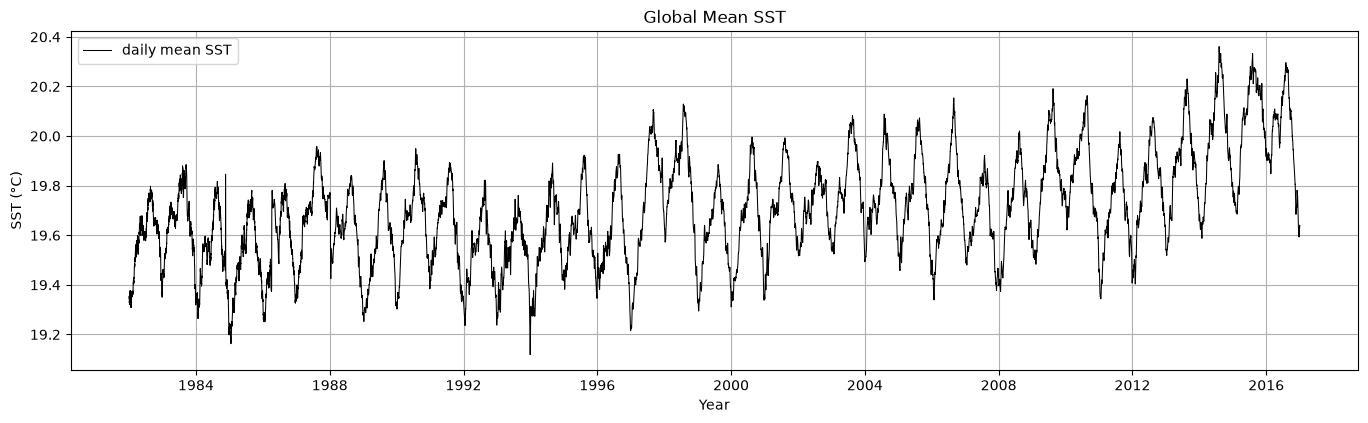

In [15]:
# We can use the toolbox plotting command to visualise the global mean SST like this: 
# the properties define the properties of the plotted line
plot(ds = sst_global_mean_ts, var ="analysed_sst_mean",
     properties = {'label': 'daily mean SST',
                  'color': 'k',
                  'linewidth': 0.75}
    )
# the matplotlib commands can be used to adapt the figure
# adding a legend
plt.legend()
# adding x- and y-label and title
plt.xlabel('Year')
plt.ylabel('SST (°C)')
plt.title('Global Mean SST')
# adapting the figure size
plt.gcf().set_size_inches(15, 4)
# adding a grid
plt.grid('both')

# this is how the figure can be saved
# plt.savefig('Global-Mean-SST-1981-2016.png')

plt.show()

Now let's take a look at yearly mean SST. First, we use the Toolbox again to compute the yearly mean with the [temporal aggregation](https://esa-climate-toolbox.readthedocs.io/en/latest/api_reference.html#esa_climate_toolbox.ops.temporal_aggregation) operation. 

In [16]:
temp_aggregation = get_op('temporal_aggregation') # fetching the operator to temporally aggregate our data

sst_yearly_mean_ts =temp_aggregation(
    ds=sst_global_mean_ts,
    method='mean', # it is also possible to compute the median, maximum and minimum
    period='1YE' # we can also use 'QS-DEC' for retrieving the mean across the DJF, MAM, JJA, SON seasons, 'MS' for Months, '8MS' would give an 8 monthly resolution, 'D' for days
) 

In [17]:
display(sst_yearly_mean_ts.analysed_sst_mean)

<xarray.DataArray 'analysed_sst_mean' (time: 35)> Size: 280B
array([19.58137128, 19.66241494, 19.5325287 , 19.5089728 , 19.56352819,
       19.71299299, 19.62002475, 19.56061359, 19.6568123 , 19.6295105 ,
       19.52761169, 19.52438183, 19.57732214, 19.62667858, 19.60286158,
       19.73941997, 19.82384039, 19.61108492, 19.64842356, 19.72566466,
       19.71546653, 19.80590444, 19.76713955, 19.76425429, 19.74318611,
       19.65215167, 19.71407136, 19.83201192, 19.85836737, 19.6887023 ,
       19.78996692, 19.88910316, 19.98914594, 20.05520329, 20.00704458])
Coordinates:
  * time     (time) datetime64[ns] 280B 1982-12-31 1983-12-31 ... 2016-12-31
Attributes:
    long_name:                        median SST from GMPE
    source:                           SST CCI V2, SST CCI V1.1, MyOcean, AVHR...
    standard_name:                    sea_surface_foundation_temperature
    units:                            kelvin
    valid_max:                        4500
    valid_min:                        -300
    ESA_Climate_Toolbox_Description:  Mean aggregated over ['lat', 'lon'] at ...

Let's look at the change of yearly mean SST over the years, some years are much warmer than others:

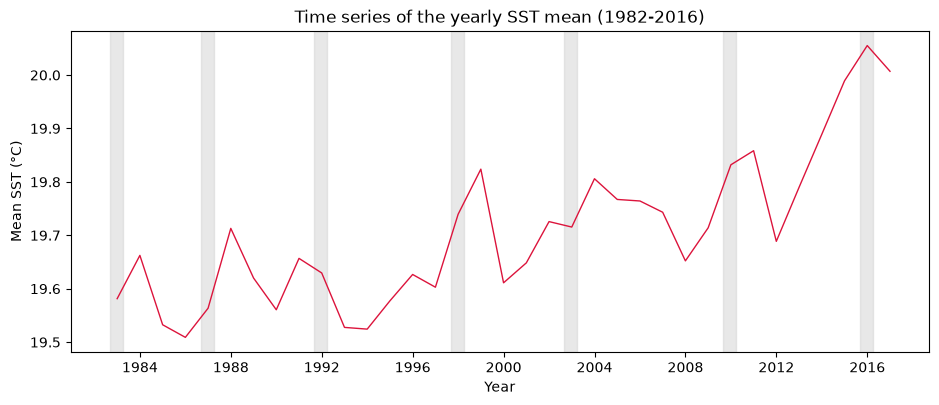

In [20]:
# we can use the toolbox plotting command as before:
plot(ds=sst_yearly_mean_ts, var="analysed_sst_mean",
     title="Time series of the yearly SST mean (1982-2016)",
     properties={'color': 'crimson', 
                 'linewidth': 1, 
                 'label': 'yearly'})

# Define El Niño winters so we can add the periods to the plot
elnino_periods = [
    (1982, 9, 1983, 3),
    (1986, 9, 1987, 3),
    (1991, 9, 1992, 3),
    (1997, 9, 1998, 3),
    (2002, 9, 2003, 3),
    (2009, 9, 2010, 3),
    (2015, 9, 2016, 3),
]

# Add grey shading for El Niño winters
ax=plt.gca() # here we are getting the current axes so we can access them and add the El Niño as shaded area in the plot
# looping through the El Niño periods an adding the time period as light grey shade
for start_y, start_m, end_y, end_m in elnino_periods:
    start_date = pd.Timestamp(start_y, start_m, 1)
    end_date = pd.Timestamp(end_y, end_m, 1) + pd.offsets.MonthEnd(0)
    ax.axvspan(start_date, end_date, color='lightgrey', alpha=0.5)
plt.ylabel('Mean SST (°C)')
plt.xlabel('Year')
plt.title("Time series of the yearly SST mean (1982-2016)")
plt.gcf().set_size_inches(10, 4)
plt.show()

In climate science, rolling means (for instance 10-year averages) are applied to suppress short-term internal variability. The SST is influenced by short-term noise like ENSO (El Niño/La Niña, ~2–7-year cycles), Volcanic eruptions that can cause temporary cooling (e.g., Pinatubo 1991) and random ocean-atmosphere fluctuations.

A 10-year rolling mean smooths out these high-frequency swings, revealing the underlying climate trend. We can apply the `rolling` function on the yearly dataset and set the time window to 10. Instead of calculating the mean here, this function can also be used for median, maximum, minimum.

Text(0.5, 0, 'Year')

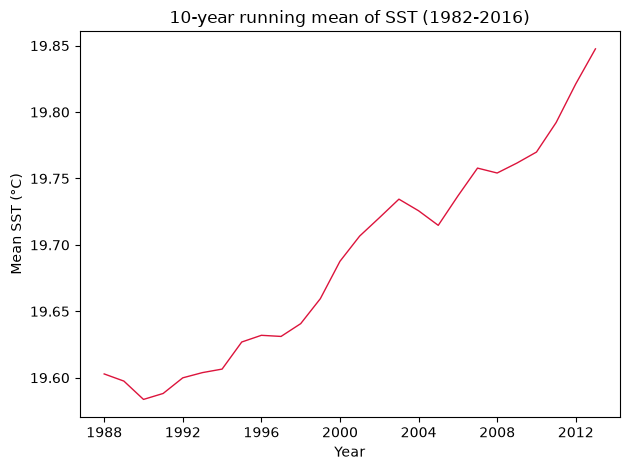

In [27]:
smooth_global_avg_ts = sst_yearly_mean_ts.analysed_sst_mean.rolling(time=10, center=True).mean()  

# we can also quickly plot it with the xarray plotting like this:
(smooth_global_avg_ts).plot(c='crimson',linewidth=1)
plt.title("10-year running mean of SST (1982-2016)")
plt.ylabel('Mean SST (°C)')
plt.xlabel('Year')

Let's have a look, when the yearly mean SST was the highest. This can easily be done by applying the `idxmax` command:

In [33]:
sst_yearly_mean_ts.analysed_sst_mean.idxmax().dt.year

<xarray.DataArray 'year' ()> Size: 8B
array(2015)
Attributes:
    long_name:                        median SST from GMPE
    source:                           SST CCI V2, SST CCI V1.1, MyOcean, AVHR...
    standard_name:                    sea_surface_foundation_temperature
    units:                            kelvin
    valid_max:                        4500
    valid_min:                        -300
    ESA_Climate_Toolbox_Description:  Mean aggregated over ['lat', 'lon'] at ...

### Let's plot our first spatial map
We will look at the SST during the year 2015.
First we select only SST values for the year 2015 by building a temporal subset using the [subset_temporal](https://esa-climate-toolbox.readthedocs.io/en/latest/api_reference.html#esa_climate_toolbox.ops.subset_temporal) command. We will use the original daily dataset in °C again.

In [14]:
# defining a time slice to capture the year 2015
time_slice= '2015-01-01, 2015-12-31'
# getting the subset_temporal operator from the toolbox:
subset_temporal_op = get_op('subset_temporal')
# now we apply the subset_temporal operator on the the dataset:
sst_sub_2015 = subset_temporal_op(ds=sst_ds_c,time_range=time_slice)
display(sst_sub_2015)

<xarray.Dataset> Size: 3GB
Dimensions:            (field_name_length: 50, fields: 16, fieldsp1: 17,
                        lat: 720, lon: 1440, time: 365)
Coordinates:
  * field_name_length  (field_name_length) int32 200B 1 2 3 4 5 ... 47 48 49 50
  * fields             (fields) int32 64B 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16
  * fieldsp1           (fieldsp1) int32 68B 1 2 3 4 5 6 7 ... 12 13 14 15 16 17
  * lat                (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.62 89.88
  * lon                (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9
  * time               (time) datetime64[ns] 3kB 2015-01-01T12:00:00 ... 2015...
Data variables:
    analysed_sst       (time, lat, lon) float64 3GB dask.array<chunksize=(11, 720, 720), meta=np.ndarray>
Attributes: (12/49)
    Conventions:                CF-1.4
    acknowledgment:             Funded by ESA
    cdm_data_type:              grid
    comment:                    
    creator_email:              science.leader@esa-sst-cci.org
    creator_name:               SST_cci
    ...                         ...
    time_coverage_start:        2015-01-01T12:00:00
    title:                      Global SST Ensemble, L4 GMPE
    uuid:                       dc0c5b25-93bf-4943-aba1-7f0de9109620
    westernmost_longitude:      -180.0
    time_coverage_duration:     P365D
    time_coverage_resolution:   P1D

We can use the [reduce](https://esa-climate-toolbox.readthedocs.io/en/latest/api_reference.html#esa_climate_toolbox.ops.reduce) operator to calculate the mean across all days. The dimension we will use is "time" so that resulting dataset contains a mean accross 2015 for each pixel according to its latitude and longitude.

In [15]:
# Getting the reduce operator
reduce = get_op('reduce')

In [16]:
sst_sub_2015_avg = reduce(
    ds = sst_sub_2015,
    var = 'analysed_sst',
    method = "mean",
    dim = "time"
)
# when printing the dimensions of the previous vs. the newly created sst for 2015, you can see that the time dimension is gone
print("Dimensions of the daily SST from 2015: ", sst_sub_2015['analysed_sst'].dims)
print("Dimensions of the dataset after applying the reduce operator: ", sst_sub_2015_avg['analysed_sst'].dims)

Dimensions of the daily SST from 2015:  ('time', 'lat', 'lon')
Dimensions of the dataset after applying the reduce operator:  ('lat', 'lon')


We will use the [plot_map](https://esa-climate-toolbox.readthedocs.io/en/latest/api_reference.html#esa_climate_toolbox.ops.plot_map) operator to visualise the newly created mean SST from 2015. 

In [4]:
# get plot map operator from the toolbox
plot_map = get_op('plot_map')

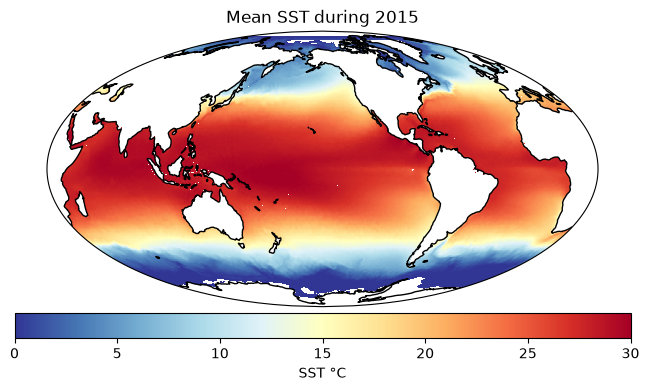

In [42]:
plot_map(
    sst_sub_2015_avg, # specifiy the dataset
    var = "analysed_sst", # define the variable to be plotted
    title = "Mean SST during 2015", # title for the figure
    projection = "Mollweide", # here, we are using Mollweide for the projection, alternatively "Robinson" is another projection which is relatively good at representing the real area,
    central_lon = -150, # since we are looking at the SST, we can shift the focus of the map to the Pacific to have most of the ocean visible 
    properties=dict(
        cmap = "RdYlBu_r",
        cbar_kwargs={       
            "shrink": 0.8, # reducing the size of the colourbar
            "aspect": 25, # aspect, pad and extend are additional commands to make the colourbar look neat (see https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.colorbar.html)
            "pad": 0.02,
            "extend": "neither",
            "label": "SST °C",
            "orientation": "horizontal"
        },
        vmin=0, # vmin and vmax control the minimum and maximum of the colorbar
        vmax=30
    )
)

But how abnormal was the SST during a very warm year? Let's focus on a particularly hot year: 2015 coinciding with an El Nino event. 

To see the actual difference, we will compute the mean over the period of data we have available, from 1982 to 2016: this will be our climatology.
First, we need to calculate the yearly mean, this time however, we will apply the temporal aggregation on the dataset including the latitude and longitude, not as before where we only looked at the time series accross the global mean.

In [45]:
temporal_aggregation = get_op('temporal_aggregation')

In [46]:
sst_yearly_mean = temporal_aggregation(
    sst_ds_c,
    period="Y"
) 
sst_yearly_mean

<xarray.Dataset> Size: 290MB
Dimensions:            (time: 35, lat: 720, lon: 1440, field_name_length: 50,
                        fields: 16, fieldsp1: 17)
Coordinates:
  * time               (time) datetime64[ns] 280B 1982-12-31 ... 2016-12-31
  * lat                (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.62 89.88
  * lon                (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9
  * field_name_length  (field_name_length) int32 200B 1 2 3 4 5 ... 47 48 49 50
  * fields             (fields) int32 64B 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16
  * fieldsp1           (fieldsp1) int32 68B 1 2 3 4 5 6 7 ... 12 13 14 15 16 17
Data variables:
    analysed_sst       (time, lat, lon) float64 290MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
Attributes: (12/49)
    Conventions:                CF-1.4
    acknowledgment:             Funded by ESA
    cdm_data_type:              grid
    comment:                    
    creator_email:              science.leader@esa-sst-cci.org
    creator_name:               SST_cci
    ...                         ...
    time_coverage_start:        1982-12-31T00:00:00
    title:                      Global SST Ensemble, L4 GMPE
    uuid:                       dc0c5b25-93bf-4943-aba1-7f0de9109620
    westernmost_longitude:      -180.0
    time_coverage_duration:     P12420D
    time_coverage_resolution:   P365D

Now we can apply the [climatology](https://esa-climate-toolbox.readthedocs.io/en/latest/api_reference.html#esa_climate_toolbox.ops.climatology) operator on the yearly dataset which will compute the mean accross all years from 1982 to 2016. 

In [47]:
climatology = get_op('climatology')

In [48]:
sst_climato = climatology(sst_yearly_mean).compute()
sst_climato

<xarray.Dataset> Size: 8MB
Dimensions:             (lat: 720, lon: 1440, time: 1, field_name_length: 50,
                         fields: 16, fieldsp1: 17, nv: 2)
Coordinates:
  * lat                 (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.62 89.88
  * lon                 (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9
  * time                (time) datetime64[ns] 8B 1982-12-31
  * field_name_length   (field_name_length) int32 200B 1 2 3 4 5 ... 47 48 49 50
  * fields              (fields) int32 64B 1 2 3 4 5 6 7 ... 11 12 13 14 15 16
  * fieldsp1            (fieldsp1) int32 68B 1 2 3 4 5 6 7 ... 12 13 14 15 16 17
Dimensions without coordinates: nv
Data variables:
    analysed_sst        (lat, lon, time) float64 8MB nan nan nan ... nan nan nan
    climatology_bounds  (time, nv) datetime64[us] 16B 1982-12-31 2016-12-31
Attributes: (12/49)
    Conventions:                CF-1.4
    acknowledgment:             Funded by ESA
    cdm_data_type:              grid
    comment:                    
    creator_email:              science.leader@esa-sst-cci.org
    creator_name:               SST_cci
    ...                         ...
    time_coverage_start:        1982-12-31T00:00:00
    title:                      Global SST Ensemble, L4 GMPE
    uuid:                       dc0c5b25-93bf-4943-aba1-7f0de9109620
    westernmost_longitude:      -180.0
    time_coverage_duration:     P12420D
    time_coverage_resolution:   P365D

Now that we have computed our climatology dataset, let's have a look at the result and plot it as we did above. 

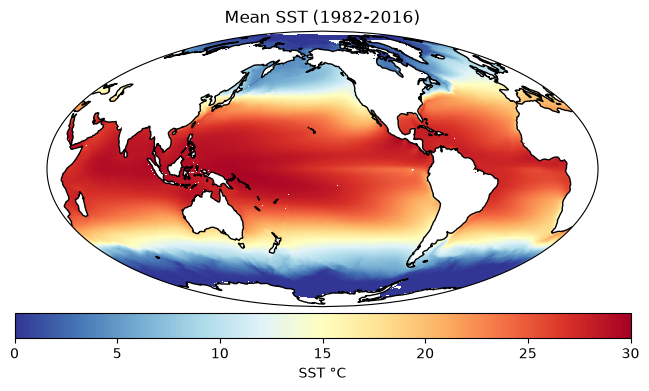

In [49]:
plot_map(
    sst_climato,
    var="analysed_sst",
    title="Mean SST (1982-2016)",
    projection = "Mollweide", 
    central_lon = -150,
    properties=dict(
        cmap = "RdYlBu_r",
        cbar_kwargs={       
            "shrink": 0.8,
            "aspect": 25,
            "pad": 0.02,
            "extend": "neither",
            "label": "SST °C",
            "orientation": "horizontal",
        },
        vmin=0,
        vmax=30
    )
)

The plot above looks visually quite similar to 2015. If we want to see the difference between the mean and the El Nino year, we can use the [diff](https://esa-climate-toolbox.readthedocs.io/en/latest/api_reference.html#esa_climate_toolbox.ops.diff) operator to subtract the datasets from each other and compute the anomaly. 

In [50]:
diff = get_op('diff')

In [51]:
diff_ds = diff(sst_sub_2015_avg, sst_climato).compute()
diff_ds

<xarray.Dataset> Size: 8MB
Dimensions:            (field_name_length: 50, fields: 16, fieldsp1: 17,
                        lat: 720, lon: 1440, time: 365)
Coordinates:
  * field_name_length  (field_name_length) int32 200B 1 2 3 4 5 ... 47 48 49 50
  * fields             (fields) int32 64B 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16
  * fieldsp1           (fieldsp1) int32 68B 1 2 3 4 5 6 7 ... 12 13 14 15 16 17
  * lat                (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.62 89.88
  * lon                (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9
  * time               (time) datetime64[ns] 3kB 2015-01-01T12:00:00 ... 2015...
Data variables:
    analysed_sst       (lat, lon) float64 8MB nan nan nan nan ... nan nan nan
Attributes: (12/45)
    Conventions:                CF-1.4
    acknowledgment:             Funded by ESA
    cdm_data_type:              grid
    comment:                    
    creator_email:              science.leader@esa-sst-cci.org
    creator_name:               SST_cci
    ...                         ...
    stop_time:                  20170101T000000Z
    summary:                    An ensemble product with input from a number ...
    title:                      Global SST Ensemble, L4 GMPE
    uuid:                       dc0c5b25-93bf-4943-aba1-7f0de9109620
    westernmost_longitude:      -180.0
    history:                    \nModified with the ESA Climate Toolbox v1.7....

For the plot of the Anomaly, we will use another colourmap and also adapt the vmin and vmax values to -2 to 2 to capture where the temperature was cooler or warmer than the mean. 

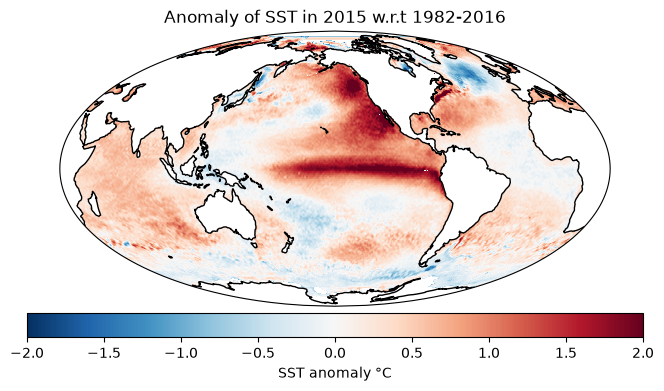

In [57]:
plot_map(
    diff_ds,
    var="analysed_sst",
    title="Anomaly of SST in 2015 w.r.t 1982-2016",
    projection = "Mollweide", 
    central_lon = -150,
    properties=dict(
        cmap="RdBu_r",
        cbar_kwargs={       
            "shrink": 0.8,
            "aspect": 25,
            "pad": 0.02,
            "extend": "neither",
            "label": "SST anomaly °C",
            "orientation": "horizontal"
        },
        vmin=-2,
        vmax=2
    )
)

## Your turn: Let's explore a few other examples with different ECVS

## Headline Example 1: "Global sea levels are rising as a result of human-caused global warming"

<div style="background-color: #fff3cd; padding: 10px; border-radius: 5px;">
👉 How would you illustrate this global increase based on previous examples?
    <div style="background-color: #fff3cd; padding: 10px; border-radius: 5px;">
💡 Display the cheat codes cells for solutions
    
💡 For more information on the impacts of how climate change affects sea level rise, have a look at <a href="https://climate.esa.int/en/Scientific-highlights/Rising-seas/">this ESA-CCI Climate Story </a>
</div>

<div style="background-color: #fff3cd; padding: 10px; border-radius: 5px;">
👉 How would you illustrate this global increase based on previous examples?
</div>

In [17]:
# Type your code here
data_id = 'esacci.SEALEVEL.mon.L4.MSLA.multi-sensor.multi-platform.MERGED.2-0.r1'


In [ ]:
# Cheat Code: opening the data
data_id = 'esacci.SEALEVEL.mon.L4.MSLA.multi-sensor.multi-platform.MERGED.2-0.r1'
sla_ds, sla_ds_name = open_data(data_id)
#display(sla_ds)

In [3]:
# Cheat Code: calculate time series
ts_mean_op = get_op('tseries_mean')

sla_global_mean_ts = ts_mean_op(
    ds=sla_ds,
    var='sla'    
).compute()

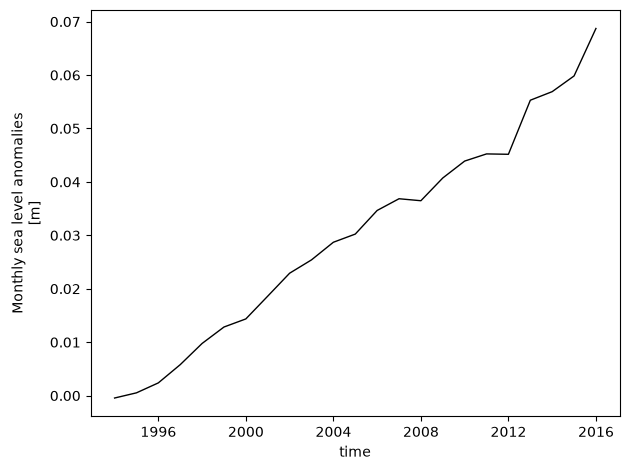

In [8]:
# Cheat Code: calculate yearly mean and plot it

temp_aggregation = get_op('temporal_aggregation') 

sla_yearly_mean_ts =temp_aggregation(
    ds=sla_global_mean_ts,
    method='mean', 
    period='1YE' 
) 

# plot the yearly mean of sea level anomaly
plot(ds=sla_yearly_mean_ts, var="sla_mean",
     properties={'color': 'k', 
                 'linewidth': 1})

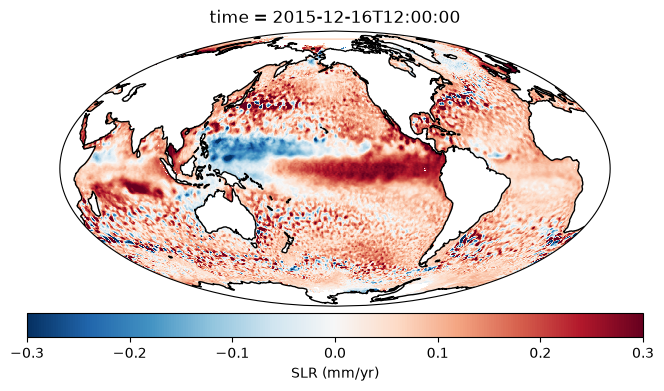

In [12]:
# Cheat Code: plotting the data as a map
plot_map = get_op('plot_map')

t = "2015-12-15"
plot_map(
    sla_ds.sel(time=t, method='nearest'),
    var="sla",
    projection = "Mollweide", 
    central_lon = -150,
    properties=dict(
        cmap="RdBu_r",
        cbar_kwargs={       
            "shrink": 0.8,
            "aspect": 25,
            "pad": 0.02,
            "extend": "neither",
            "label": "SLR (mm/yr)",
            "orientation": "horizontal"
        },
        vmin=-0.3,
        vmax=0.3
    )
)

## Headline Example 2: "Catastrophic wildfires hitting southeastern Australia in 2019-20 made worse due to climate change"

<div style="background-color: #fff3cd; padding: 10px; border-radius: 5px;">
👉 Which ESA-CCI climate variables from the .zarr datastore would use to look at the conditions that made the wildfires in Australia in 2019-2020 so severe ? 

👉 How would you plot spatial maps of these conditions during this period ? How would you compare them to average conditions?
</div>

In [39]:
#Type your code here




<div style="background-color: #fff3cd; padding: 10px; border-radius: 5px;">
💡 Display the cheat codes cells for solutions
    
💡 For more information on this extreme event, have a look at <a href="https://www.bbc.com/news/science-environment-51742646">this BBC News article </a> and 
<a href="https://earth.esa.int/eogateway/gallery/wildfires-in-australia-2019">this ESA article  </a>. Note that ESA-CCI has developped a Bruned Area product, not yet available on the CCI .zarr datastore of the Toolbox but you can find out more <a href="https://climate.esa.int/en/projects/fire/">here </a>.
</div>

In [7]:
# Focus on South-Eastern Australia (bbox: 140, -45, 155, -25) during 2019 heatwave
bbox = (140, -45, 155, -25)  
geom = shapely.geometry.box(*bbox)
centroid = geom.centroid
m = folium.Map(location=[centroid.y, centroid.x], zoom_start=7)
folium.GeoJson(geom.__geo_interface__).add_to(m)
m

In [8]:
# We suggest to use the following monthly LST data
data_id = 'ESACCI-LST-L3S-LST-IRCDR_-0.01deg_1MONTHLY_DAY-1995-2020-fv3.00.zarr'
LST_ds, LST_ds_name = open_data(data_id, var_names="lst")
LST_ds 

<xarray.Dataset> Size: 2TB
Dimensions:  (time: 294, lat: 18000, lon: 36000, channel: 2)
Coordinates:
  * time     (time) datetime64[ns] 2kB 1995-08-01 1995-09-01 ... 2020-12-01
  * lat      (lat) float32 72kB -90.0 -89.99 -89.98 -89.97 ... 89.97 89.98 89.99
  * lon      (lon) float32 144kB -180.0 -180.0 -180.0 ... 180.0 180.0 180.0
  * channel  (channel) float64 16B 11.0 12.0
Data variables:
    lst      (time, lat, lon) float64 2TB dask.array<chunksize=(1, 2250, 2250), meta=np.ndarray>
Attributes: (12/42)
    Conventions:                CF-1.8
    catalogue_url:              https://catalogue.ceda.ac.uk/uuid/6babb8d9a8d...
    cdm_data_type:              grid
    comment:                    These data were produced as part of the ESA L...
    creator_email:              djg20@le.ac.uk
    creator_name:               University of Leicester Surface Temperature G...
    ...                         ...
    summary:                    This file contains level L3S global land surf...
    time_coverage_duration:     P1M
    time_coverage_end:          19700101T000001Z
    time_coverage_resolution:   P1M
    time_coverage_start:        19700101T000001Z
    title:                      ESA LST CCI land surface temperature time ser...

In [9]:
# Cheat code for regional selection
subset_spatial_op = get_op('subset_spatial')
LST_sub = subset_spatial_op(ds=LST_ds, region=bbox)
# display spatial subset
LST_sub

<xarray.Dataset> Size: 7GB
Dimensions:  (time: 294, lat: 2002, lon: 1502, channel: 2)
Coordinates:
  * time     (time) datetime64[ns] 2kB 1995-08-01 1995-09-01 ... 2020-12-01
  * lat      (lat) float32 8kB -45.01 -44.99 -44.99 ... -25.02 -25.01 -25.0
  * lon      (lon) float32 6kB 140.0 140.0 140.0 140.0 ... 155.0 155.0 155.0
  * channel  (channel) float64 16B 11.0 12.0
Data variables:
    lst      (time, lat, lon) float64 7GB dask.array<chunksize=(1, 1, 1502), meta=np.ndarray>
Attributes: (12/44)
    Conventions:                CF-1.8
    catalogue_url:              https://catalogue.ceda.ac.uk/uuid/6babb8d9a8d...
    cdm_data_type:              grid
    comment:                    These data were produced as part of the ESA L...
    creator_email:              djg20@le.ac.uk
    creator_name:               University of Leicester Surface Temperature G...
    ...                         ...
    time_coverage_end:          19700101T000001Z
    time_coverage_resolution:   P1M
    time_coverage_start:        19700101T000001Z
    title:                      ESA LST CCI land surface temperature time ser...
    geospatial_bounds_crs:      CRS84
    geospatial_bounds:          POLYGON((139.989990234375 -45.01000213623047,...

In [10]:
# Cheat code for Converting to Celsius
arithmetics = get_op('arithmetics')
LST_sub_cs = arithmetics(
    ds=LST_sub,
    ops="-273.15"
)

In [18]:
# Cheat code for Temporal Subset
time_slice='2019-12-01, 2019-12-31'
subset_temporal_op = get_op('subset_temporal')
LST_sub_2019_Dec_cs = subset_temporal_op(ds=LST_sub_cs,time_range=time_slice)
LST_sub_2019_Dec_cs.compute()

<xarray.Dataset> Size: 24MB
Dimensions:  (channel: 2, lat: 2002, lon: 1502, time: 1)
Coordinates:
  * channel  (channel) float64 16B 11.0 12.0
  * lat      (lat) float32 8kB -45.01 -44.99 -44.99 ... -25.02 -25.01 -25.0
  * lon      (lon) float32 6kB 140.0 140.0 140.0 140.0 ... 155.0 155.0 155.0
  * time     (time) datetime64[ns] 8B 2019-12-01
Data variables:
    lst      (time, lat, lon) float64 24MB nan nan nan nan ... nan nan nan nan
Attributes: (12/42)
    Conventions:                CF-1.8
    catalogue_url:              https://catalogue.ceda.ac.uk/uuid/6babb8d9a8d...
    cdm_data_type:              grid
    comment:                    These data were produced as part of the ESA L...
    creator_email:              djg20@le.ac.uk
    creator_name:               University of Leicester Surface Temperature G...
    ...                         ...
    summary:                    This file contains level L3S global land surf...
    time_coverage_end:          2019-12-01T00:00:00
    time_coverage_start:        2019-12-01T00:00:00
    title:                      ESA LST CCI land surface temperature time ser...
    geospatial_bounds_crs:      CRS84
    geospatial_bounds:          POLYGON((139.989990234375 -45.01000213623047,...

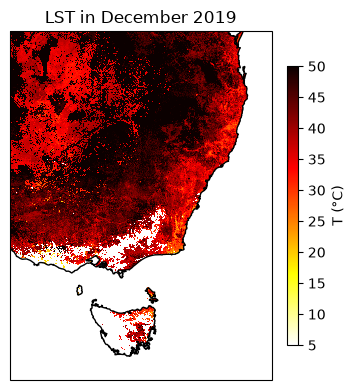

In [48]:
# Cheat Code for plotting
plot_map = get_op('plot_map')

plot_map(    
    LST_sub_2019_Dec_cs,
    var="lst",
    title="LST in December 2019",
    properties=dict(
        cmap="hot_r",
        cbar_kwargs={       
            "shrink": 0.8,
            "aspect": 25,
            "pad": 0.02,
            "extend": "neither",
            "label": "T (°C)",
            "orientation": "vertical"
        },
        vmin=5,
        vmax=50
    ),
    region=bbox
)

In [44]:
# Cheat Code: How abnormal was this event ? - Computation of Climatology
climatology = get_op('climatology')
LST_climato = climatology(LST_sub_cs)

LST_climato

<xarray.Dataset> Size: 289MB
Dimensions:             (time: 12, lat: 2002, lon: 1502, channel: 2, nv: 2)
Coordinates:
  * time                (time) datetime64[ns] 96B 1995-01-01 ... 1995-12-01
  * lat                 (lat) float32 8kB -45.01 -44.99 -44.99 ... -25.01 -25.0
  * lon                 (lon) float32 6kB 140.0 140.0 140.0 ... 155.0 155.0
  * channel             (channel) float64 16B 11.0 12.0
Dimensions without coordinates: nv
Data variables:
    lst                 (time, lat, lon) float64 289MB dask.array<chunksize=(1, 1, 1502), meta=np.ndarray>
    climatology_bounds  (time, nv) datetime64[us] 192B dask.array<chunksize=(1, 2), meta=np.ndarray>
Attributes: (12/44)
    Conventions:                CF-1.8
    catalogue_url:              https://catalogue.ceda.ac.uk/uuid/6babb8d9a8d...
    cdm_data_type:              grid
    comment:                    These data were produced as part of the ESA L...
    creator_email:              djg20@le.ac.uk
    creator_name:               University of Leicester Surface Temperature G...
    ...                         ...
    time_coverage_end:          19700101T000001Z
    time_coverage_resolution:   P1M
    time_coverage_start:        19700101T000001Z
    title:                      ESA LST CCI land surface temperature time ser...
    geospatial_bounds_crs:      CRS84
    geospatial_bounds:          POLYGON((139.989990234375 -45.01000213623047,...

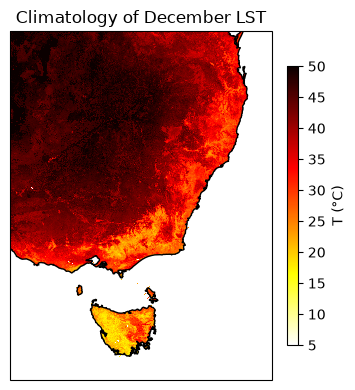

In [49]:
plot_map(    
    LST_climato,
    var="lst",
    title="Climatology of December LST",
    indexers={"time": "1995-12-01"},
    properties=dict(
        cmap="hot_r",
        cbar_kwargs={       
            "shrink": 0.8,
            "aspect": 25,
            "pad": 0.02,
            "extend": "neither",
            "label": "T (°C)",
            "orientation": "vertical"
        },
        vmin=5,
        vmax=50
    ),
    region=bbox
)

<div style="background-color: #fff3cd; padding: 10px; border-radius: 5px;">
👉 Bonus Question: Now compute the anomaly of December LST in 2019 with respect to 1995-2020
    </div>

In [26]:
# type your code here


You can do the same for soil moisture now.

In [50]:
# Cheat Code to open the data 
#!This data is daily and not monthly -
data_id = 'ESACCI-SOILMOISTURE-L3S-SSMV-COMBINED-1978-2020-fv05.3.zarr'
#cci_zarr_store.describe_data(data_id)
SM_ds, SM_ds_name = open_data(data_id)
SM_ds

<xarray.Dataset> Size: 575GB
Dimensions:         (time: 15402, lat: 720, lon: 1440)
Coordinates:
  * time            (time) datetime64[ns] 123kB 1978-11-01 ... 2020-12-31
  * lat             (lat) float64 6kB 89.88 89.62 89.38 ... -89.38 -89.62 -89.88
  * lon             (lon) float64 12kB -179.9 -179.6 -179.4 ... 179.6 179.9
Data variables:
    dnflag          (time, lat, lon) float32 64GB dask.array<chunksize=(16, 720, 720), meta=np.ndarray>
    flag            (time, lat, lon) float32 64GB dask.array<chunksize=(16, 720, 720), meta=np.ndarray>
    freqbandID      (time, lat, lon) float32 64GB dask.array<chunksize=(16, 720, 720), meta=np.ndarray>
    mode            (time, lat, lon) float32 64GB dask.array<chunksize=(16, 720, 720), meta=np.ndarray>
    sensor          (time, lat, lon) float32 64GB dask.array<chunksize=(16, 720, 720), meta=np.ndarray>
    sm              (time, lat, lon) float32 64GB dask.array<chunksize=(16, 720, 720), meta=np.ndarray>
    sm_uncertainty  (time, lat, lon) float32 64GB dask.array<chunksize=(16, 720, 720), meta=np.ndarray>
    t0              (time, lat, lon) datetime64[ns] 128GB dask.array<chunksize=(16, 720, 720), meta=np.ndarray>
Attributes: (12/40)
    Conventions:                CF-1.7
    cdm_data_type:              Grid
    comment:                    This dataset was produced with funding of the...
    contact:                    cci_sm_contact@eodc.eu
    creator_email:              cci_sm_contact@eodc.eu
    creator_name:               Department of Geodesy and Geoinformation, Tec...
    ...                         ...
    time_coverage_duration:     P42Y
    time_coverage_end:          2020-12-31 00:00:00
    time_coverage_resolution:   P1D
    time_coverage_start:        1978-11-01 00:00:00
    title:                      ESA CCI Surface Soil Moisture COMBINED active...
    tracking_id:                174f51a4-6a06-4352-a712-4d3f77bd8166

In [56]:
#Type your code here:
data_id = 'ESACCI-SOILMOISTURE-L3S-SSMV-COMBINED-1978-2020-fv05.3.zarr'



In [52]:
#Type your code here:





In [53]:
# Example of Plots: How abnormal was this event ?